Saved predictions checked with FEM: 90 test shapes, eight FM draws per input, original scale. Spectral error is mean absolute relative eigenvalue error (%) on the supplied modes.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

root = Path("..") if Path.cwd().name == "notebooks" else Path(".")
sys.path.insert(0, str(root / "training/regression"))
from spectral_ablation_metrics import align_to

results = root / "results/spectral_ablation_balanced_20261028/spectral_consistency_20261029"
rows = pd.read_csv(results / "per_draw.csv")
with np.load(results / "forward_spectra.npz") as saved:
    forward = dict(saved)
valid = rows[(rows.status == "ok") & (rows.model != "reference")]
print(f"{(rows.status != 'ok').sum()} invalid or failed samples excluded.")
(100 * valid.groupby(["n_eig", "model"]).observed_mare.agg(["mean", "median"])).round(2)

5 invalid or failed samples excluded.


mean  median
n_eig model                   
5     flow        9.95    1.45
      regression  4.07    2.97
30    flow        6.00    1.73
      regression  3.26    1.94

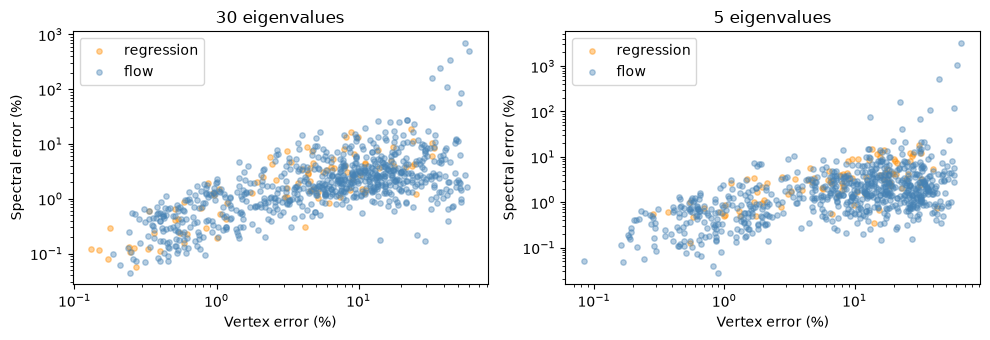

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, n in zip(axes, (30, 5)):
    for model, color in (("regression", "darkorange"), ("flow", "steelblue")):
        group = valid[(valid.model == model) & (valid.n_eig == n)]
        ax.scatter(100 * group.shape_error, 100 * group.observed_mare,
                   label=model, color=color, alpha=.4, s=15)
    ax.set(xscale="log", yscale="log", title=f"{n} eigenvalues",
           xlabel="Vertex error (%)", ylabel="Spectral error (%)")
    ax.legend()
fig.tight_layout()
plt.show()

In [3]:
# Best of eight FM draws, ranked by the input spectrum only.
fm = valid[valid.model == "flow"]
best = fm.loc[fm.groupby(["n_eig", "test_id"]).observed_mare.idxmin()]
(100 * best.groupby("n_eig")[["observed_mare", "high25_mare"]].mean()).rename(
    columns={"observed_mare": "Input error (%)", "high25_mare": "Modes 6–30 (%)"}).round(2)

,Input error (%),Modes 6–30 (%)
n_eig,,
5,0.77,1.31
30,0.96,0.96


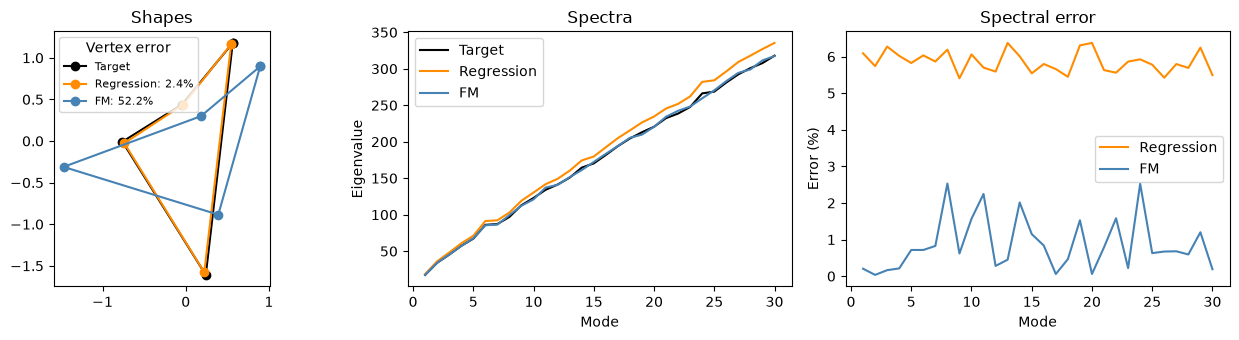

In [4]:
# An example selected after inspecting the results.
case = rows[(rows.test_id == 1160) & (rows.n_eig == 30)]
reg = case[case.model == "regression"].index[0]
fm = case[(case.model == "flow") & (case.draw_id == 3)].index[0]
target = forward["targets"][fm]
target = target - target.mean(axis=0)
modes = np.arange(1, 31)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
closed = np.vstack([target, target[:1]])
axes[0].plot(*closed.T, "o-", color="black", label="Target")
axes[1].plot(modes, forward["target_spectra"][fm], color="black", label="Target")
for i, name, color in ((reg, "Regression", "darkorange"), (fm, "FM", "steelblue")):
    polygon = align_to(target, forward["polygons"][i])
    closed = np.vstack([polygon, polygon[:1]])
    error = rows.loc[i, "shape_error"]
    axes[0].plot(*closed.T, "o-", color=color, label=f"{name}: {error:.1%}")
    axes[1].plot(modes, forward["spectra"][i], color=color, label=name)
    axes[2].plot(modes, 100 * forward["per_mode_relative_error"][i], color=color, label=name)
axes[0].set(title="Shapes", aspect="equal")
axes[0].legend(title="Vertex error", loc="upper left", fontsize=8)
axes[1].set(title="Spectra", xlabel="Mode", ylabel="Eigenvalue")
axes[2].set(title="Spectral error", xlabel="Mode", ylabel="Error (%)")
for ax in axes[1:]:
    ax.legend()
fig.tight_layout()
plt.show()